# Bài 5 — Câu 3: Pearson trên Heart Disease

**Sinh viên:** Nguyễn Đức Vinh — **MSSV:** 6451071087

Dữ liệu theo `TaiLieuLab02.pdf`. Mỗi notebook chạy độc lập.

Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087
Kích thước dữ liệu Heart sau xử lý: (303, 14)
Ma trận Pearson:
                           age    sex  chest_pain_type  resting_blood_pressure  cholesterol  fasting_blood_sugar  rest_ecg  max_heart_rate_achieved  exercise_induced_angina  st_depression  st_slope  num_major_vessels  thalassemia
age                      1.000 -0.098           -0.069                   0.279        0.214                0.121    -0.116                   -0.399                    0.097          0.210    -0.169              0.276        0.068
sex                     -0.098  1.000           -0.049                  -0.057       -0.198                0.045    -0.058                   -0.044                    0.142          0.096    -0.031              0.118        0.210
chest_pain_type         -0.069 -0.049            1.000                   0.048       -0.077                0.094     0.044                    0.296                   -0.394         -0.149     0.120       

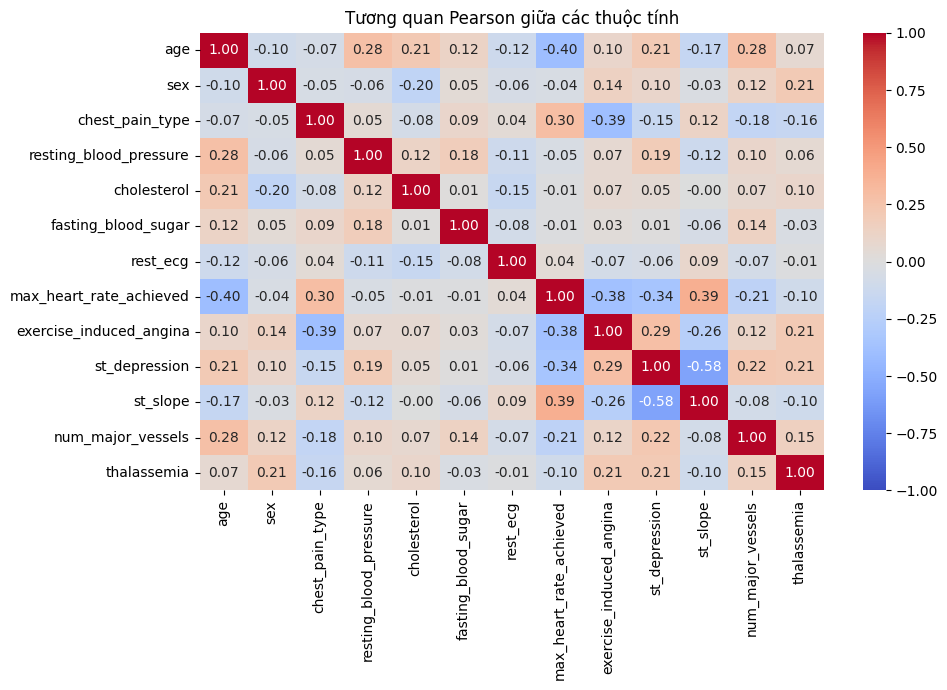

Các cột có thể loại vì tương quan rất cao: Không có


In [2]:
print("Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

# Khi chạy trên Colab, nếu chưa có file trong thư mục hiện tại, tự tải từ Drive công khai.
DATA_DIR = Path('data') if Path('data').exists() else Path('.')
DRIVE_IDS = {
    'adult.data.csv': '1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB',
    'adult.test.csv': '1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD',
    'winequality-red.csv': '1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH',
    'heart.csv': '10N9jGzMn-MagDWXORdP-qIpwC3omZJHb',
    'mushrooms.csv': '11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW',
    'test_image_Bai7.jpg': '1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx'
}
def get_file(filename):
    p = DATA_DIR / filename
    if not p.exists():
        import subprocess, sys
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'gdown'])
            import gdown
        gdown.download(id=DRIVE_IDS[filename], output=str(p), quiet=False)
    if not p.exists():
        raise FileNotFoundError('Không tải được ' + filename + '. Hãy tải từ Drive và upload lên Colab.')
    return p

DATASET = 'heart'
data = pd.read_csv(get_file('heart.csv'))
cols = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
        'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
        'exercise_induced_angina', 'st_depression', 'st_slope',
        'num_major_vessels', 'thalassemia', 'target']
assert len(data.columns) == len(cols), 'Dữ liệu Heart không đúng 14 cột'
data.columns = cols
data.replace(r'^\s*\?\s*$', np.nan, regex=True, inplace=True)
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')
data = data.dropna().reset_index(drop=True)
print('Kích thước dữ liệu Heart sau xử lý:', data.shape)

# Pearson tính trên các cột số; không đưa nhãn quyết định vào phân tích tương quan thuộc tính.
numeric = data.drop(columns=['target']).select_dtypes(include=np.number)
corr = numeric.corr(method='pearson')
print('Ma trận Pearson:')
print(corr.round(3).to_string())
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Tương quan Pearson giữa các thuộc tính')
plt.tight_layout(); plt.show()
# Ngưỡng tham khảo |r| > 0.90, xét một nửa tam giác trên để tránh trùng lặp.
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_corr = [c for c in upper.columns if any(upper[c] > 0.90)]
print('Các cột có thể loại vì tương quan rất cao:', drop_corr if drop_corr else 'Không có')
